# code_226 · Capstone: relational maintenance evidence from raw entities to a budgeted queue

**Book:** section 43.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials and explicitly acquired cached checkpoints. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_43_GUIDE.md), [execution evidence](../CHAPTER_43_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_226).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Complete projects retain framing, data provenance, baseline comparisons, fitting/selection/calibration boundaries, independent assessment, measured resources and decision authority. Variable resource observations are stored separately from deterministic scientific RESULTS. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or new asset is added; existing pinned checkpoints are reused. See [asset acquisition and licence](../CHAPTER_43_ASSETS.md).


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8026;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8026


## Frame the event and build a historical feature table without future records
 Predict a generated actionable finding within thirty days, reported five days later. Eighty independent buildings each contain six members. Source buildings 0–19 predict on day 60 and 20–39 on day 120; development 40–49 predict on180; calibration 50–59 on220; final 60–79 on270. Source labels mature before development, development before calibration, and calibration before final. Generate building/member tables and three measurement records per member at prediction−60,−20,+10; each measurement becomes available two days later. The last record is future information. As-of joins admit both event_time<=prediction_time and available_time<=prediction_time. Features are member load, age, material, latest crack indicator and the mean latest crack indicator of other members in the same building. Generated outcome probability depends on own and relational condition. No feature uses a future inspection finding. Alter every future measurement by999 and require the feature matrix to remain identical.


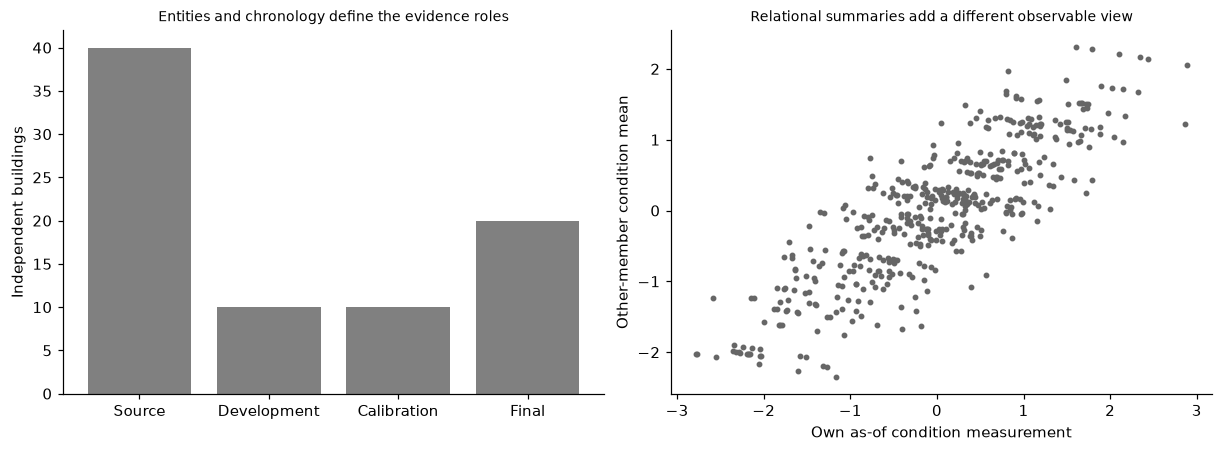

In [2]:
import hashlib,os,importlib.metadata
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
buildings=pd.DataFrame({'building_id':np.arange(80),'material':rng.binomial(1,.25,80),'corrosion':rng.normal(size=80)});members=[];measurements=[]
for b in range(80):
    origin=60 if b<20 else (120 if b<40 else (180 if b<50 else (220 if b<60 else 270)))
    for member in range(6):
        mid=b*6+member;load=float(rng.uniform(0,2));age=float(rng.uniform(0,5));condition=float(buildings.loc[b,'corrosion']+rng.normal(scale=.5));members.append({'building_id':b,'member_id':mid,'prediction_day':origin,'load':load,'age':age,'material':int(buildings.loc[b,'material'])})
        for lag in [-60,-20,10]:measurements.append({'member_id':mid,'event_day':origin+lag,'available_day':origin+lag+2,'crack':condition+.004*lag+float(rng.normal(scale=.1))})
members=pd.DataFrame(members);measurements=pd.DataFrame(measurements)
def asof_features(table):
    joined=members.merge(table,on='member_id',validate='one_to_many');admitted=joined[(joined.event_day<=joined.prediction_day)&(joined.available_day<=joined.prediction_day)].sort_values(['member_id','event_day']).groupby('member_id',sort=True).tail(1).sort_values('member_id');assert len(admitted)==480 and np.all(admitted.available_day<=admitted.prediction_day);own=admitted.crack.to_numpy();mean_other=(pd.Series(own).groupby(members.building_id).transform('sum').to_numpy()-own)/5;return np.c_[members[['load','age','material']].to_numpy(),own,mean_other]
X=asof_features(measurements);changed=measurements.copy();future=changed.event_day.to_numpy()>np.repeat(members.prediction_day.to_numpy(),3);changed.loc[future,'crack']+=999;assert np.array_equal(X,asof_features(changed));group=members.building_id.to_numpy();Y=rng.binomial(1,expit(-1+.5*X[:,0]+.15*X[:,1]-.3*X[:,2]+.7*X[:,3]+1.0*X[:,4]));inspections=pd.DataFrame({'member_id':members.member_id,'outcome_end_day':members.prediction_day+30,'report_available_day':members.prediction_day+35,'finding':Y});source=group<40;dev=(group>=40)&(group<50);cal=(group>=50)&(group<60);final=group>=60;assert inspections.loc[source,'report_available_day'].max()<members.loc[dev,'prediction_day'].min();assert inspections.loc[dev,'report_available_day'].max()<members.loc[cal,'prediction_day'].min();assert inspections.loc[cal,'report_available_day'].max()<members.loc[final,'prediction_day'].min();assert set(group[source]).isdisjoint(set(group[dev])|set(group[cal])|set(group[final]));historical=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(X[group<20],Y[group<20]);historical_Brier=float(np.mean((historical.predict_proba(X[(group>=20)&(group<40)])[:,1]-Y[(group>=20)&(group<40)])**2));RESULTS.update(building_roles=[40,10,10,20],members_per_building=6,source_scalar_labels=240,development_scalar_labels=60,calibration_scalar_labels=60,final_scalar_labels=120,asof_admitted_feature_rows=480,excluded_future_measurements=int(future.sum()),future_measurement_intervention_difference=0.,group_overlap=0,historical_earlier_to_later_source_Brier=historical_Brier);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Source','Development','Calibration','Final'],[40,10,10,20],color='.5');axes[0].set(ylabel='Independent buildings',title='Entities and chronology define the evidence roles');axes[1].scatter(X[:,3],X[:,4],s=8,color='.4');axes[1].set(xlabel='Own as-of condition measurement',ylabel='Other-member condition mean',title='Relational summaries add a different observable view');plt.show()


## Compare actual model families, including one explicitly cached foundation predictor
 Fit source-only scaled logistic, fifty-round/seven-leaf histogram boosting and a5–16–1 tanh neural model trained for 180 Adam steps with weight decay 0.01. A separate logistic ablation omits the other-member aggregate. The real TabPFN v2 classifier uses all 240 permitted source rows as context, one estimator and float32 CPU inference. Follow the explicit [asset guide](../CHAPTER_43_ASSETS.md) before ordinary execution; verify the immutable cached checkpoint hash and use Hub offline mode. Other models use float64 arithmetic. Upstream pretraining compute differs, so this is a local task comparison rather than equal-total-compute benchmarking. Select among the four full-feature families by development Brier only, then fit one sigmoid probability remapping on the independent calibration buildings. No final finding selects family, architecture, context size, threshold or calibration state.


/Users/imeshekanayake/Documents/Projects/017- ML Book/examples/.venv/lib/python3.14/site-packages/tabpfn/validation.py:234: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  _validate_num_samples_for_cpu(


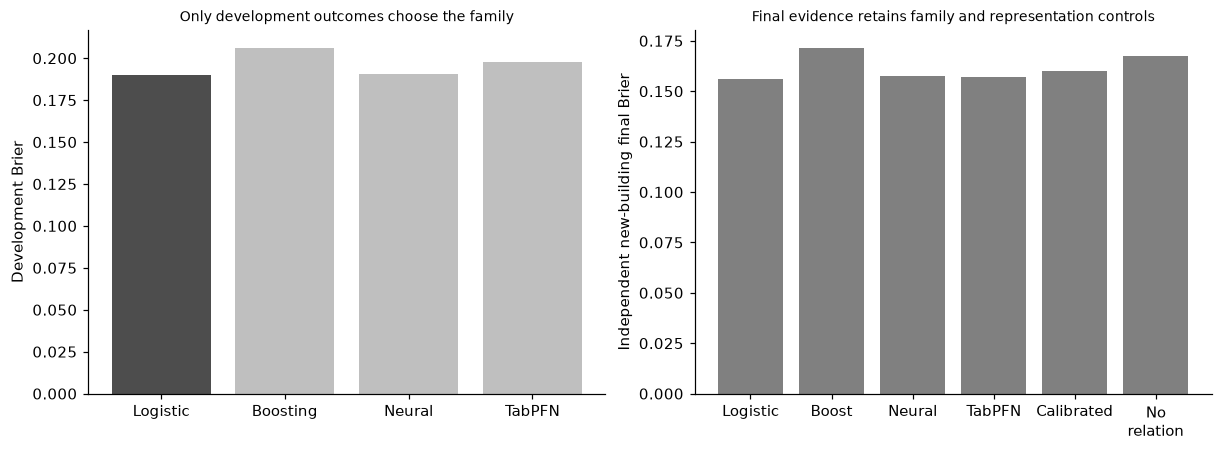

In [3]:
linear=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(X[source],Y[source]);tree=HistGradientBoostingClassifier(max_iter=50,max_leaf_nodes=7,early_stopping=False,random_state=SEED).fit(X[source],Y[source]);ablation=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(X[source,:4],Y[source]);scale=StandardScaler().fit(X[source]);net=nn.Sequential(nn.Linear(5,16),nn.Tanh(),nn.Linear(16,1));optimizer=torch.optim.Adam(net.parameters(),lr=.015,weight_decay=.01);tx=torch.tensor(scale.transform(X[source]));ty=torch.tensor(Y[source],dtype=torch.float64)[:,None]
for _ in range(180):
    optimizer.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(net(tx),ty);loss.backward();optimizer.step()
net.eval()
def neural(x):
    with torch.no_grad():return torch.sigmoid(net(torch.tensor(scale.transform(x)))).numpy()[:,0]
os.environ['HF_HUB_OFFLINE']='1'
from tabpfn import TabPFNClassifier
VERSIONS['tabpfn']=importlib.metadata.version('tabpfn');ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (p/'examples.json').is_file());checkpoint=ROOT/'build/model-cache/models--Prior-Labs--TabPFN-v2-clf/snapshots/f851f2a3c941544733b712d8c0f96dfae9b28862/tabpfn-v2-classifier-v2_default.ckpt';assert checkpoint.is_file(),'Explicitly acquire Chapter43 assets first; see CHAPTER_43_ASSETS.md';blob=checkpoint.read_bytes();assert len(blob)==29009539 and hashlib.sha256(blob).hexdigest()=='cf8c519c01eaf1613ee91239006d57b1c806ff5f23ac1aeb1315ba1015210e49';del blob;foundation=TabPFNClassifier(n_estimators=1,model_path=checkpoint,device='cpu',inference_precision=torch.float32,n_preprocessing_jobs=1,random_state=SEED).fit(X[source],Y[source]);foundation.predict_proba(X[source][:8]);weights_hash=lambda:hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for m in foundation.models_ for p in m.parameters())).hexdigest();frozen=weights_hash();predictors={'Logistic':lambda x:linear.predict_proba(x)[:,1],'Boosting':lambda x:tree.predict_proba(x)[:,1],'Neural':neural,'TabPFN':lambda x:foundation.predict_proba(x)[:,1]};development={name:float(np.mean((fn(X[dev])-Y[dev])**2)) for name,fn in predictors.items()};chosen=min(development,key=development.get);native_cal=np.clip(predictors[chosen](X[cal]),1e-8,1-1e-8);calibrator=LogisticRegression(C=1).fit(np.log(native_cal/(1-native_cal))[:,None],Y[cal]);assert calibrator.coef_[0,0]>0
def calibrated(x):
    p=np.clip(predictors[chosen](x),1e-8,1-1e-8);return calibrator.predict_proba(np.log(p/(1-p))[:,None])[:,1]
final_predictions={name:fn(X[final]) for name,fn in predictors.items()};p=calibrated(X[final]);final_scores={name:float(np.mean((v-Y[final])**2)) for name,v in final_predictions.items()};assert weights_hash()==frozen;assert np.all(np.isfinite(p)) and np.all((p>=0)&(p<=1));RESULTS.update(development_Brier=development,development_selected_family=chosen,final_native_Brier=final_scores,final_calibrated_selected_Brier=float(np.mean((p-Y[final])**2)),final_logistic_without_relational_Brier=float(np.mean((ablation.predict_proba(X[final,:4])[:,1]-Y[final])**2)),probability_calibration_labels=60,calibration_logit_slope=float(calibrator.coef_[0,0]),pretrained_parameters_unchanged_after_initialization=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(4),list(development.values()),color=['.3' if name==chosen else '.75' for name in development]);axes[0].set(xticks=range(4),xticklabels=list(development),ylabel='Development Brier',title='Only development outcomes choose the family');axes[1].bar(range(6),list(final_scores.values())+[RESULTS['final_calibrated_selected_Brier'],RESULTS['final_logistic_without_relational_Brier']],color='.5');axes[1].set(xticks=range(6),xticklabels=['Logistic','Boost','Neural','TabPFN','Calibrated','No\nrelation'],ylabel='Independent new-building final Brier',title='Final evidence retains family and representation controls');plt.show()


## Deliver uncertainty, subgroup support, a fixed visit queue and measured workload
 Resample the twenty final buildings, keeping all six members together, to obtain a paired conditional bootstrap interval for calibrated chosen-family minus native logistic Brier. This interval conditions on all fitting and selection, excludes model-refitting uncertainty and is not a collection of independent member seeds. Report material-group counts and Brier/error without a fairness certificate. Allocate exactly twelve inspection visits to the highest calibrated probabilities in the 120-case final cohort; record observed findings captured and selected count. That is inspection yield under the generated event, not causal repair benefit or structural clearance. Measure three warmed 120-row prediction calls for each actual implementation and keep timings outside deterministic RESULTS. VisualA aligns all five capstones to framing, provenance, baselines, independent checks and bounded decisions; their numerical studies are separate generated experiments, not one shared benchmark dataset.


,material,n,positives,Brier,error
0,0,84,23,0.135409,0.178571
1,1,36,12,0.217418,0.388889


,model,request_rows,median_seconds,repetitions
0,Logistic,120,0.000089,3
1,Boosting,120,0.000175,3
2,Neural,120,0.000066,3
3,TabPFN,120,0.111978,3


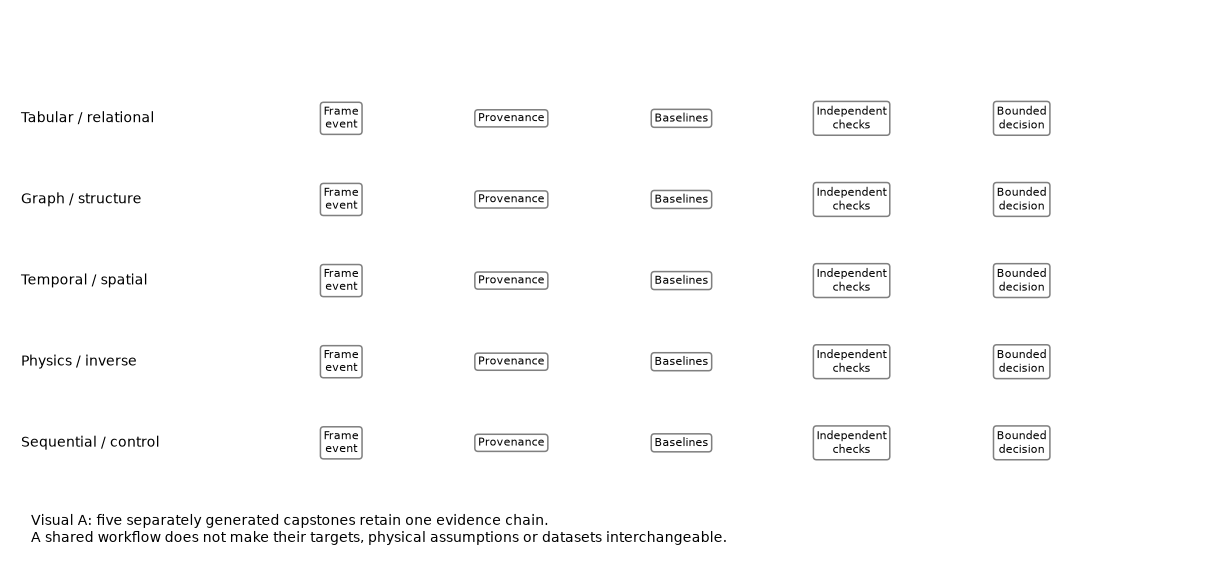

In [4]:
gf=group[final];yf=Y[final];paired=(p-yf)**2-(final_predictions['Logistic']-yf)**2;building_loss=np.array([paired[gf==b].mean() for b in range(60,80)]);draw=rng.integers(0,20,(2000,20));interval=np.quantile(building_loss[draw].mean(1),[.025,.975]).tolist();subgroups=[]
for material in [0,1]:
    mask=X[final,2]==material;subgroups.append({'material':material,'n':int(mask.sum()),'positives':int(yf[mask].sum()),'Brier':float(np.mean((p[mask]-yf[mask])**2)),'error':float(np.mean((p[mask]>=.5)!=yf[mask]))})
queue=np.argsort(-p,kind='stable')[:12];assert len(queue)==12 and len(set(queue))==12;MEASUREMENTS={'warm_forward_profiles':[]}
for name,fn in predictors.items():
    fn(X[final]);durations=[]
    for _ in range(3):
        start=time.perf_counter();fn(X[final]);durations.append(time.perf_counter()-start)
    MEASUREMENTS['warm_forward_profiles'].append({'model':name,'request_rows':120,'median_seconds':float(np.median(durations)),'repetitions':3})
RESULTS.update(final_buildings_bootstrap_unit=20,paired_Brier_difference=float(building_loss.mean()),paired_building_bootstrap95=interval,bootstrap_conditions_on_fitted_and_selected_state=True,final_material_subgroups=subgroups,inspection_budget=12,inspection_queue_observed_findings=int(yf[queue].sum()),inspection_queue_members=members.loc[final,'member_id'].to_numpy()[queue].tolist(),inspection_yield_is_not_causal_repair_benefit=True);display(pd.DataFrame(subgroups));display(pd.DataFrame(MEASUREMENTS['warm_forward_profiles']));fig,ax=plt.subplots(figsize=(11,5));ax.axis('off');names=['Tabular / relational','Graph / structure','Temporal / spatial','Physics / inverse','Sequential / control'];stages=['Frame event','Provenance','Baselines','Independent checks','Bounded decision'];ax.set(xlim=(0,6),ylim=(0,6))
for i,name in enumerate(names):
    ax.text(.05,4.8-i*.9,name,fontsize=9,va='center')
    for j,stage in enumerate(stages):ax.text(1.65+j*.85,4.8-i*.9,stage.replace(' ','\n',1),fontsize=7,ha='center',va='center',bbox={'boxstyle':'round','facecolor':'white','edgecolor':'.5'})
ax.text(.1,.1,'Visual A: five separately generated capstones retain one evidence chain.\nA shared workflow does not make their targets, physical assumptions or datasets interchangeable.',fontsize=9);plt.show()


In [5]:
summary={'example_id':'code_226','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual entity measurement and inspection tables with grouped historical as-of joins and future-record intervention', 'transparent tree own neural and pinned TabPFN baselines with relational ablation', 'independent development selection calibration cohort and final building bootstrap subgroup audit', 'actual inference workload measurements separate from deterministic results and fixed inspection budget'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual entity measurement and inspection tables with grouped historical as-of joins and future-record intervention", "transparent tree own neural and pinned TabPFN baselines with relational ablation", "independent development selection calibration cohort and final building bootstrap subgroup audit", "actual inference workload measurements separate from deterministic results and fixed inspection budget"], "elapsed_seconds": 2.667, "example_id": "code_226", "hardware": "Darwin arm64 CPU", "resource_measurements": {"warm_forward_profiles": [{"median_seconds": 8.900000830180943e-05, "model": "Logistic", "repetitions": 3, "request_rows": 120}, {"median_seconds": 0.00017512499471195042, "model": "Boosting", "repetitions": 3, "request_rows": 120}, {"median_seconds": 6.587497773580253e-05, "model": "Neural", "repetitions": 3, "request_rows": 120}, {"median_seconds": 0.11197812500176951, "model": "TabPFN", "repetitions": 3, "request_rows": 120}